<a href="https://colab.research.google.com/github/alluanasilva-impa/pontos-de-ruptura-climaticos/blob/main/IC_Teste_de_Simulacoes_Ressonancia_Estocastica.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Langevin's Equation

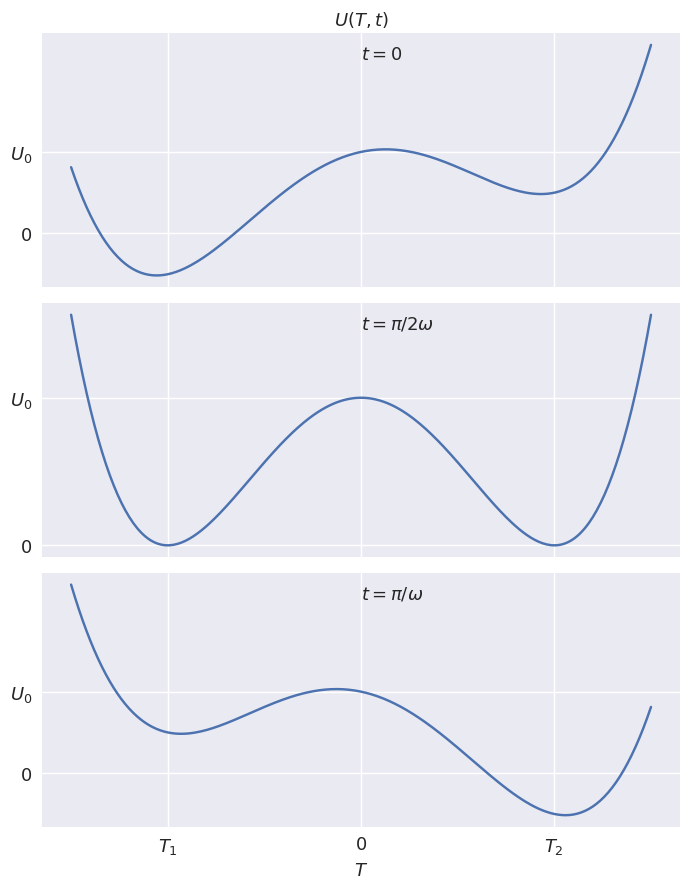

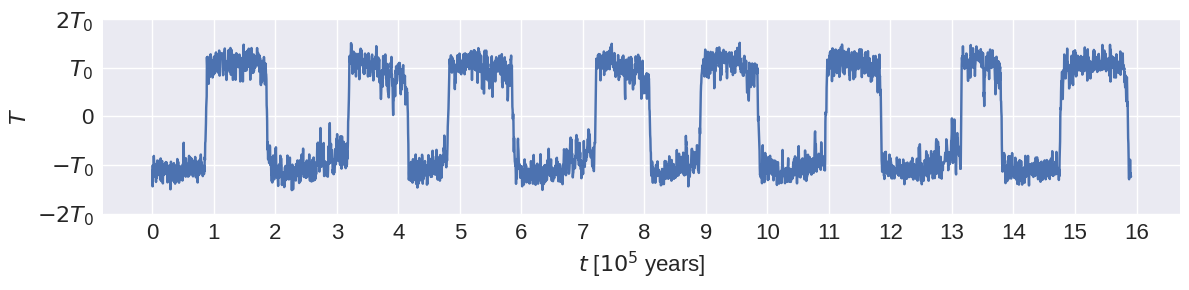

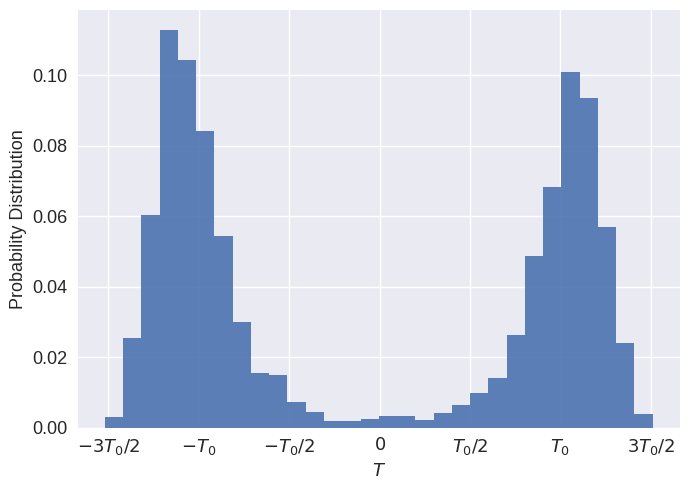

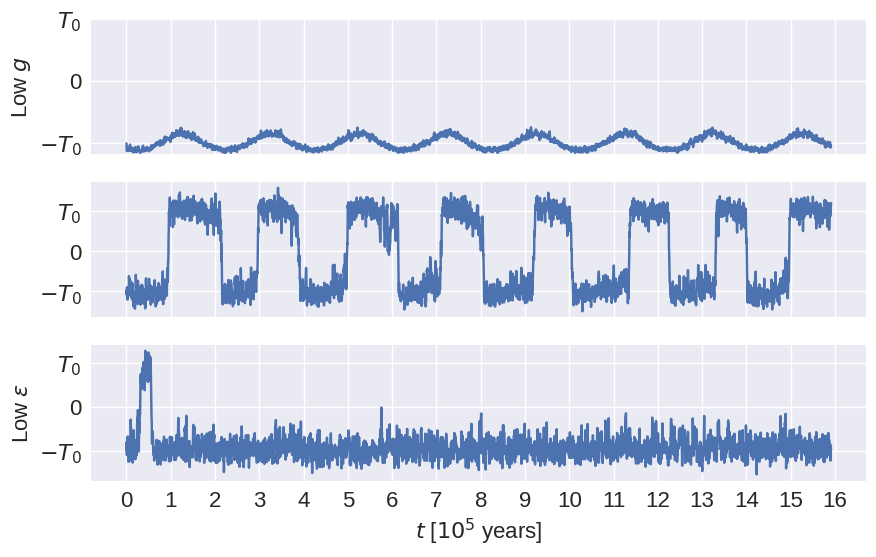

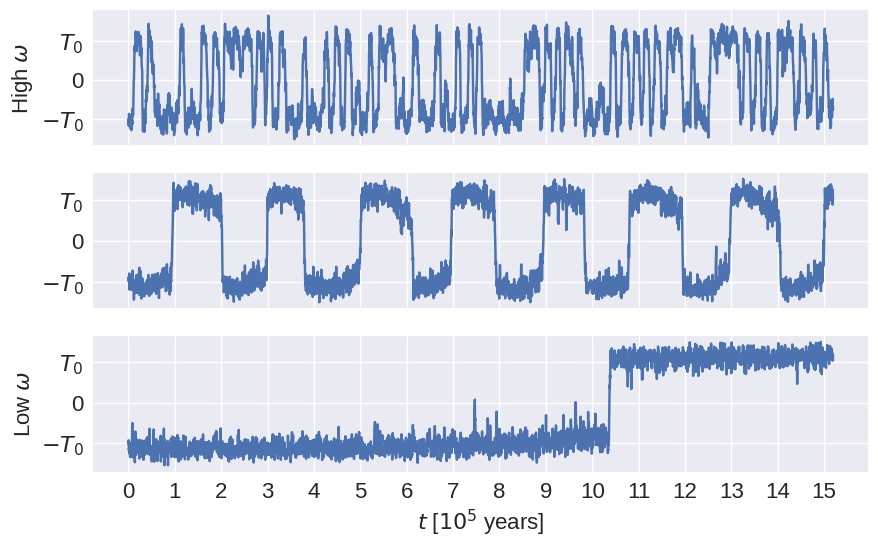

In [1]:
# Statistical Mechanics 2023.1
# Author: Marcelo Ismerio Oliveira, Bruno Honorato Scorzelli
# This code provides a numerical solution to the stochastic differential equation
# dT/dt = -U'(T,t) + gη(T)
# where U(T) = 16*U_0 * (T-T_1)*(T-T_1) * (T-T_2)*(T-T_2) / (T_1-T_2)**(-4) + epsilon*T*cos(w*t)

from numpy import *
from matplotlib import pyplot as plt
plt.style.use('seaborn-v0_8')

# Potential
def U(T, t, parameters):
  U_0, T_1, T_2, epsilon, w, g = parameters
  return 16*U_0 * (T-T_1)*(T-T_1) * (T-T_2)*(T-T_2) / (T_1-T_2)**(4) + epsilon*T*cos(w*t)

# Force due to the potential and extra force
def U_prime(T, t, parameters):
  U_0, T_1, T_2, epsilon, w, g = parameters
  return 32*U_0 * (T-T_1)*(T-T_2) * (2*T-T_1-T_2) / (T_1-T_2)**(4) + epsilon*cos(w*t-pi/4) # a phase has been added for style. It is not relevant for the discussion.


# Gaussian noise of mean 0 and standard deviation 1
def eta(dt):
  return random.normal(0,1)

def solve_langevin(parameters, tmax=400, PLOT=True):

  # Define time step and range
  t0 = 0
  dt = 0.001
  time_range = arange(t0, tmax, dt)

  # Save arrays for plotting
  save_frequency = tmax/4
  save_times = []
  save_T = []

  T = parameters[1] # initial value
  g = parameters[-1]
  for step, t in enumerate(time_range):

    D1 = -U_prime(T, t, parameters)
    D2 = g*g
    T = T + D1*dt + sqrt(D2*dt)*eta(t)
    if step%save_frequency == 0:
        save_T.append(T)
        save_times.append(t)

  # Plotting (optional)
  if PLOT == True:
    T_2 = parameters[2]
    plt.style.use('seaborn-v0_8')
    fig, ax = plt.subplots(figsize=(12, 3))
    ax.plot(save_times, save_T)
    ax.set_xticks(arange(0, pi/w*17, pi/w), arange(0, 17, 1), fontsize=16)
    ax.set_xlabel(r'$t$ [$10^5$ years]', fontsize=16)
    ax.set_yticks(arange(-2*T_2, 3*T_2, T_2), [r'$-2T_0$', r'$-T_0$', '0', r'$T_0$', r'$2T_0$'], fontsize=16)
    ax.set_ylabel(r'$T$', fontsize=16)
    plt.tight_layout()
    plt.savefig('EstMec_1_StochasticResonance.png', dpi=600)
    plt.show()

  return save_times, save_T

###########################################################################################
# Figure 0: Potential
parameters = [100, -10, 10, 5, 0.25/2, 7]
U_0, T_1, T_2, epsilon, w, g = parameters
T = linspace(-15, 15, 300)
plt.style.use('seaborn-v0_8')
fig, ax = plt.subplots(3, 1, figsize=(7, 9), sharex=True)
ax[0].plot(T, U(T, 0, parameters))
ax[1].plot(T, U(T, pi/2/w, parameters))
ax[2].plot(T, U(T, pi/w, parameters))
ax[0].set_yticks(array([0, U_0]), [r'$0$', r'$U_0$'], fontsize=13)
ax[2].set_xlabel(r'$T$', fontsize=13)
ax[1].set_yticks(array([0, U_0]), [r'$0$', r'$U_0$'], fontsize=13)
ax[2].set_yticks(array([0, U_0]), [r'$0$', r'$U_0$'], fontsize=13)
ax[0].set_title(r'$U(T, t)$', fontsize=13)
ax[2].set_xticks(array([T_1, 0, T_2]), [r'$T_1$', r'$0$', r'$T_2$'], fontsize=13)
ax[0].text(0.5, 0.9, r'$t = 0$', transform=ax[0].transAxes, fontsize=13)
ax[1].text(0.5, 0.9, r'$t = \pi/2\omega$', transform=ax[1].transAxes, fontsize=13)
ax[2].text(0.5, 0.9, r'$t = \pi/\omega$', transform=ax[2].transAxes, fontsize=13)
plt.tight_layout()
plt.savefig('EstMec_0_Potential.png', dpi=600)
plt.show()

###########################################################################################
# Figure 1: Stochastic Ressonance
x, y = solve_langevin([100, -10, 10, 16, 0.25/2, 7], PLOT=True)

###########################################################################################
# Figure 2: PDF of the temperature.
# Plot Histogram for Prob Distribution
plt.style.use('seaborn-v0_8')
fig, ax = plt.subplots(figsize=(7, 5))
plt.yticks(fontsize=13)
plt.hist(y,ec="white", alpha=0.9, bins=30, density=True)
ax.set_xticks(arange(-15, 20, 5), [r'$-3T_0/2$', r'$-T_0$', r'$-T_0/2$', r'$0$', r'$T_0/2$', r'$T_0$', r'$3T_0/2$'], fontsize=13)
ax.set_xlabel(r'$T$', fontsize=13)
ax.set_ylabel(r'Probability Distribution', fontsize=13)
plt.tight_layout()
plt.savefig('EstMec_2_PDF.png', dpi=600)
plt.show()

###########################################################################################
# Figure 3: Comparison between different values of noise and amplitude. Everything else is fixed.
fig, ax = plt.subplots(3, 1, figsize = (10,6), sharex=True)
T_2 = 10
# Low noise
ax1 = ax[0]
x, y = solve_langevin([100, -10, 10, 10, 0.25/2, 1], PLOT=False) #epsilon = 10, omega= 0.25/2, g = 1
ax1.plot(x, y)
ax1.set_yticks(arange(-T_2, 2*T_2, T_2), [r'$-T_0$', '0', r'$T_0$'], fontsize=16)
ax1.set_ylabel(r'Low $g$', fontsize=16)

# High noise, high force strength
ax2 = ax[1]
x, y = solve_langevin([100, -10, 10, 10, 0.25/2, 7], PLOT=False) #epsilon = 10, omega= 0.25/2, g = 7
ax2.plot(x, y)
ax2.set_yticks(arange(-T_2, 2*T_2, T_2), [r'$-T_0$', '0', r'$T_0$'], fontsize=16)

# Low force strength
ax3 = ax[2]
x, y = solve_langevin([100, -10, 10, 1, 0.25/2, 7], PLOT=False) #epsilon = 1, omega= 0.25/2, g = 7
ax3.plot(x, y)
ax3.set_yticks(arange(-T_2, 2*T_2, T_2), [r'$-T_0$', '0', r'$T_0$'], fontsize=16)
w = 0.25/2
ax3.set_xticks(arange(0, pi/w*17, pi/w), arange(0, 17, 1), fontsize=16)
ax3.set_xlabel(r'$t$ [$10^5$ years]', fontsize=16)
ax3.set_ylabel(r'Low $\varepsilon$', fontsize=16)

plt.savefig('EstMec_3_ComparisonAmplitude.png', dpi=600)
plt.show()

###########################################################################################
# Figure 4: Comparison between different values of frequency. Everything else is fixed.
fig, ax = plt.subplots(3, 1, figsize = (10,6), sharex=True)
T_2 = 10

# High Frequency
ax1 = ax[0]
w = 1
x, y = solve_langevin([100, -10, 10, 17, w, 7], PLOT=False)
ax1.plot(x, y)
ax1.set_yticks(arange(-T_2, 2*T_2, T_2), [r'$-T_0$', '0', r'$T_0$'], fontsize=16)
ax1.set_ylabel(r'High $\omega$', fontsize=16)

# Kramer Frequency
ax2 = ax[1]
U_0 = 100
g = 7
w_k = sqrt(2)*U_0/10*exp(-2*U_0/g/g)/2
x, y = solve_langevin([100, -10, 10, 17, w_k, 7], PLOT=False)
ax2.plot(x, y)
ax2.set_yticks(arange(-T_2, 2*T_2, T_2), [r'$-T_0$', '0', r'$T_0$'], fontsize=16)

# Low frequency
ax3 = ax[2]
w = 0.05/5
x, y = solve_langevin([100, -10, 10, 17, w, 7], PLOT=False)
ax3.plot(x, y)
ax3.set_yticks(arange(-T_2, 2*T_2, T_2), [r'$-T_0$', '0', r'$T_0$'], fontsize=16)
ax3.set_xticks(arange(0, pi/w_k*16, pi/w_k), arange(0, 16, 1), fontsize=16)
ax3.set_xlabel(r'$t$ [$10^5$ years]', fontsize=16)
ax3.set_ylabel(r'Low $\omega$', fontsize=16)

plt.savefig('EstMec_4_ComparisonOmega.png', dpi=600)
plt.show()

# Simulação do Processo de Wiener

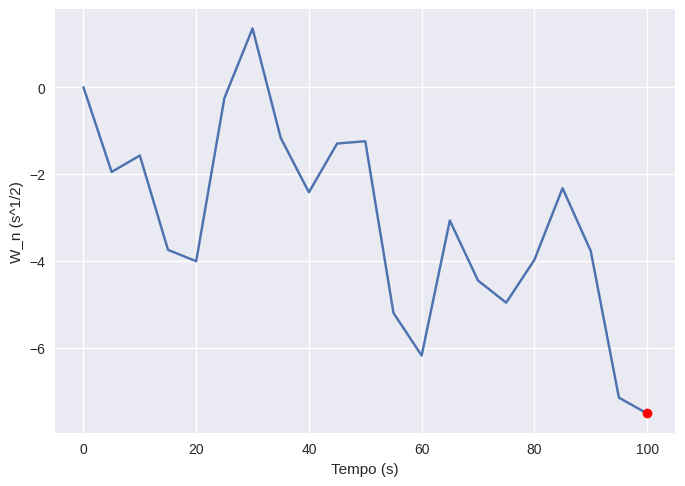

In [2]:
# Declaração de bibliotecas:
from numpy import *
from matplotlib import pyplot as plt

#Sorteio de incremento:
def eta(dt):
  return random.normal(0,1)

# Condições iniciais:
t = 0
W_0 = 0
# Tempo total:
T = 100
#Total de passos:
N = 20
#tamanho do passo
d_t = T/N
#Registro de evolução:
tempo = []
tempo.append(t)
W = []
W.append(W_0)
W_t = W_0

while t < T:
  # Incremento de Wiener:
  d_W_n = sqrt(d_t)*eta(t)
  W_t += d_W_n
  W.append(W_t)
  t += d_t
  tempo.append(t)

####### PLOTAGEM ######
x = tempo
y = W
plt.plot(x,y)
plt.xlabel('Tempo (s)')
plt.ylabel('W_n (s^1/2)')
plt.grid(True)
plt.plot(tempo[-1], W[-1], 'ro')
plt.show()



# Simulação da Equação de Langevin

Equação Diferencial Estocástica de Langevin para a temperatura T:

$$ \frac{dT}{dt} = - U'(T,t) + gη(t)$$

Multiplicando tudo por $dt$:

$$ dT = - U'(T,t)\,dt + gη(t)\,dt$$

Pela definição de Incremento de Wiener:

$$ dT = - U'(T,t)\,dt + g\,dW_t $$

Discretizando

$$dt \rightarrow \Delta t$$  
$$dT \rightarrow \Delta T = T_{n+1} - T_n$$  
$$dW_t \rightarrow \Delta W_n = \sqrt{\Delta t}$$  

Substituindo esses termos na equação:

$$T_{n+1} - T_n = -U'(T_n, t_n)\Delta t + g \sqrt{\Delta t}\,\eta_n$$

Equação do potencial:  
$$U(T,t) = \frac{16 U_0 (T-T_1)^2 (T-T_2)^2}{(T_1 - T_2)^4} + \epsilon \, T\, \cos{\omega t}$$

### Teste inicial

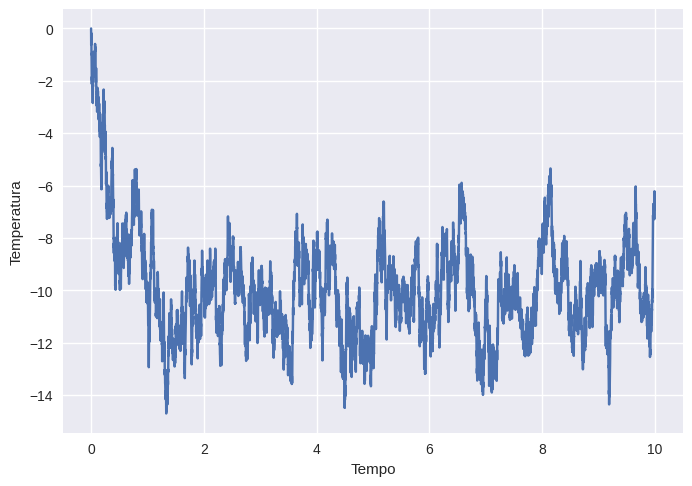

In [3]:
# Declaração de bibliotecas:
from numpy import *
from matplotlib import pyplot as plt

#Sorteio de incremento:
def eta(dt):
  return random.normal(0,1)


# Função da energia
def U(T,t,parametros):
  U_0, T_1, T_2, epsilon, w, g = parametros
  return 16*U_0 * (T-T_1)*(T-T_1) * (T-T_2)*(T-T_2) / (T_1-T_2)**(4) + epsilon*T*cos(w*t)

# Derivada da energia em relação ao tempo
def derivada_U (T,t,parametros):
 U_0, T_1, T_2, epsilon, w, g = parametros
 return 32*U_0 * (T-T_1)*(T-T_2) * (2*T-T_1-T_2) / (T_1-T_2)**(4) + epsilon*cos(w*t-pi/4) #mantive a fase para comparar com os gráficos originais

def solve_langevin(parametros, max_iter=10000):
  i = 0
  t = 0  #tempo inicial
  dt = 0.001 #passo
  T = 0.0 #temperatura inicial
  g = parametros[-1]

  lista_tempo = [t]
  lista_temperatura = [T]

  #Laço de evolução temporal (Euler-Maruyama)
  while i < max_iter:

    drift = -derivada_U(T,t,parametros) * dt
    difusao = g * sqrt(dt) * eta(dt)
    T = T + drift + difusao
    t = t + dt
    i += 1

    lista_temperatura.append(T)
    lista_tempo.append(t)


  return lista_tempo, lista_temperatura


########## MAIN ###########
parametros = [100, -10, 10, 5, 0.25/2, 7]
U_0, T_1, T_2, epsilon, w, g = parametros

tempo, temperatura = solve_langevin(parametros)

plt.plot(tempo, temperatura)
plt.xlabel('Tempo')
plt.ylabel('Temperatura')
plt.grid(True)
plt.show()

## Comportamento da função após variações em $ ϵ $ e $ g $:

$T_{período} = \frac{2 \pi}{\omega}$  
$\omega = 0.125$  
$T_{período} = 50s$  
Para 6 iterações: $T_{max}
 = 300s$

### Variando g:

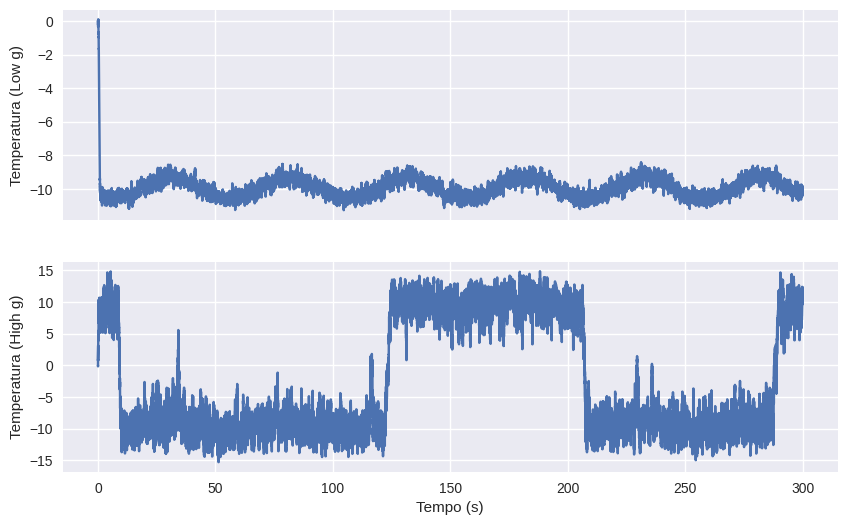

In [4]:
# Declaração de bibliotecas:
from numpy import *
from matplotlib import pyplot as plt

#Sorteio de incremento:
def eta(dt):
  return random.normal(0,1)


# Função da energia
def U(T,t,parametros):
  U_0, T_1, T_2, epsilon, w, g = parametros
  return 16*U_0 * (T-T_1)*(T-T_1) * (T-T_2)*(T-T_2) / (T_1-T_2)**(4) + epsilon*T*cos(w*t)

# Derivada da energia em relação ao tempo
def derivada_U (T,t,parametros):
 U_0, T_1, T_2, epsilon, w, g = parametros
 return 32*U_0 * (T-T_1)*(T-T_2) * (2*T-T_1-T_2) / (T_1-T_2)**(4) + epsilon*cos(w*t-pi/4) #mantive a fase para comparar com os gráficos originais

def solve_langevin(parametros, tmax=300):
  i = 0
  t = 0  #tempo inicial
  dt = 0.001 #passo
  T = 0.0 #temperatura inicial
  g = parametros[-1]

  lista_tempo = [t]
  lista_temperatura = [T]

  #Laço de evolução temporal (Euler-Maruyama)
  while t < tmax:

    drift = -derivada_U(T,t,parametros) * dt
    difusao = g * sqrt(dt) * eta(dt)
    T = T + drift + difusao
    t = t + dt

    lista_temperatura.append(T)
    lista_tempo.append(t)


  return lista_tempo, lista_temperatura


  ########## MAIN ###########
# g alto: 7.0
parametros_alto = [100, -10, 10, 5, 0.25/2, 7.0]
U_0, T_1, T_2, epsilon, w, g = parametros_alto
tempo_alto, temp_alto = solve_langevin(parametros_alto)

# g baixo: 1.0
parametros_baixo = [100, -10, 10, 5, 0.25/2, 1.0]
U_0, T_1, T_2, epsilon, w, g = parametros_baixo
tempo_baixo, temp_baixo = solve_langevin(parametros_baixo)

## Subplots empilhados: ##
fig, (ax1, ax2) = plt.subplots(2,1, figsize=(10,6), sharex=True)

# gráfico superior (baixo g):
ax1.plot(tempo_baixo,temp_baixo)
ax1.set_ylabel('Temperatura (Low g)')

# gráfico inferior (alto g):
ax2.plot(tempo_alto,temp_alto)
ax2.set_ylabel('Temperatura (High g)')
ax2.set_xlabel('Tempo (s)')

plt.show()

### Variando $\epsilon$:

<>:63: SyntaxWarning: invalid escape sequence '\e'
<>:67: SyntaxWarning: invalid escape sequence '\e'
<>:63: SyntaxWarning: invalid escape sequence '\e'
<>:67: SyntaxWarning: invalid escape sequence '\e'
/tmp/ipykernel_2370/934906140.py:63: SyntaxWarning: invalid escape sequence '\e'
  ax1.set_ylabel('Temperatura (Low $\epsilon$)')
/tmp/ipykernel_2370/934906140.py:67: SyntaxWarning: invalid escape sequence '\e'
  ax2.set_ylabel('Temperatura (High $\epsilon$)')


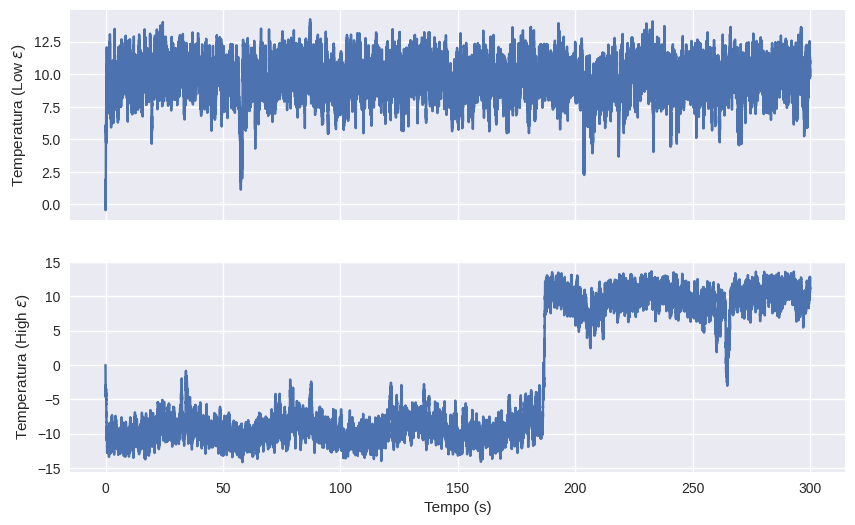

In [5]:
# Declaração de bibliotecas:
from numpy import *
from matplotlib import pyplot as plt

#Sorteio de incremento:
def eta(dt):
  return random.normal(0,1)


# Função da energia
def U(T,t,parametros):
  U_0, T_1, T_2, epsilon, w, g = parametros
  return 16*U_0 * (T-T_1)*(T-T_1) * (T-T_2)*(T-T_2) / (T_1-T_2)**(4) + epsilon*T*cos(w*t)

# Derivada da energia em relação ao tempo
def derivada_U (T,t,parametros):
 U_0, T_1, T_2, epsilon, w, g = parametros
 return 32*U_0 * (T-T_1)*(T-T_2) * (2*T-T_1-T_2) / (T_1-T_2)**(4) + epsilon*cos(w*t-pi/4) #mantive a fase para comparar com os gráficos originais

def solve_langevin(parametros, tmax=300):
  i = 0
  t = 0  #tempo inicial
  dt = 0.001 #passo
  T = 0.0 #temperatura inicial
  g = parametros[-1]

  lista_tempo = [t]
  lista_temperatura = [T]

  #Laço de evolução temporal (Euler-Maruyama)
  while t < tmax:

    drift = -derivada_U(T,t,parametros) * dt
    difusao = g * sqrt(dt) * eta(dt)
    T = T + drift + difusao
    t = t + dt

    lista_temperatura.append(T)
    lista_tempo.append(t)


  return lista_tempo, lista_temperatura


  ########## MAIN ###########

# Mantendo o g moderado: 5.0
# epsilon alto: 8
parametros_alto = [100, -10, 10, 8, 0.25/2, 5]
U_0, T_1, T_2, epsilon, w, g = parametros_alto
tempo_alto, temp_alto = solve_langevin(parametros_alto)

# epsilon baixo: 2
parametros_baixo = [100, -10, 10, 2, 0.25/2, 5]
U_0, T_1, T_2, epsilon, w, g = parametros_baixo
tempo_baixo, temp_baixo = solve_langevin(parametros_baixo)

## Subplots empilhados: ##
fig, (ax1, ax2) = plt.subplots(2,1, figsize=(10,6), sharex=True)

# gráfico superior (baixo g):
ax1.plot(tempo_baixo,temp_baixo)
ax1.set_ylabel('Temperatura (Low $\epsilon$)')

# gráfico inferior (alto g):
ax2.plot(tempo_alto,temp_alto)
ax2.set_ylabel('Temperatura (High $\epsilon$)')
ax2.set_xlabel('Tempo (s)')

plt.show()

Diagrama de fases de g e epsilon  

Diagrama com epsilon, tau e g

Deixar a simulação do código original rodando por mais tempo

Aplicar decomposição de fourier em algum dos gráficos

### Testes variados

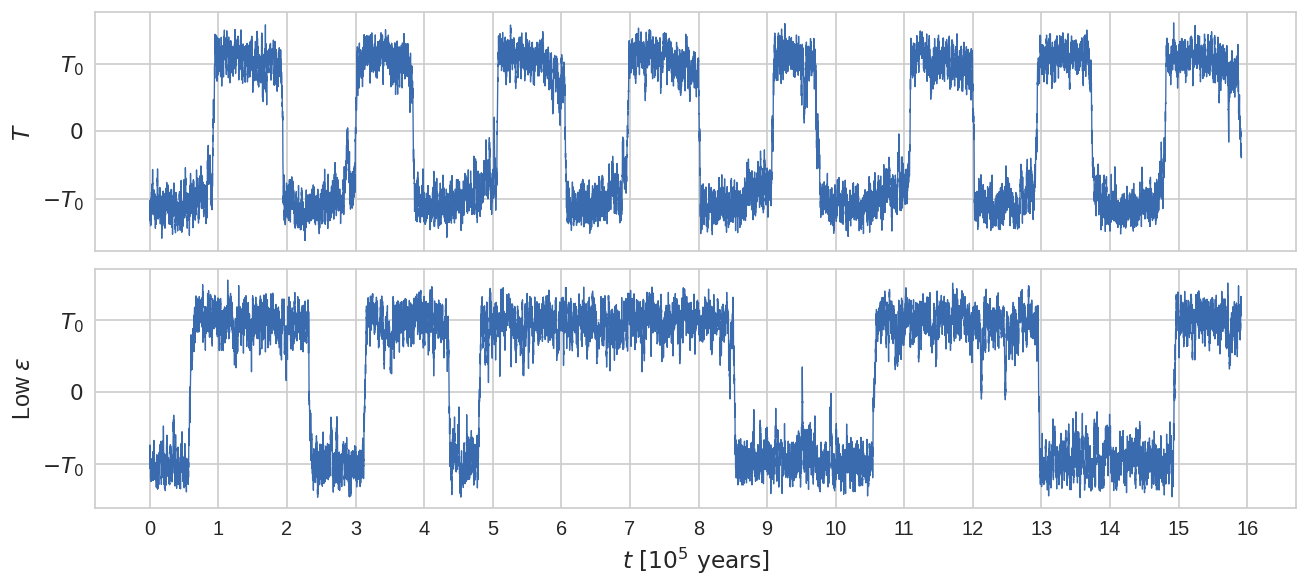

In [6]:
import numpy as np
import matplotlib.pyplot as plt

# Estilo visual do gráfico (sem fontes personalizadas)
plt.style.use('seaborn-v0_8-whitegrid')

# Derivada do potencial bistável U'(T, t)
def derivada_U(T, t, U_0, T_1, T_2, epsilon, w):
    f_pocos = 32 * U_0 * (T - T_1) * (T - T_2) * (2 * T - T_1 - T_2) / ((T_1 - T_2)**4)
    f_forcante = epsilon * np.cos(w * t - np.pi / 4)
    return f_pocos + f_forcante

# Solver da EDE de Langevin
def simular_langevin(U_0=100, T_1=-10, T_2=10, epsilon=16, w=0.125, g=7, tmax=400, dt=0.001):
    time_range = np.arange(0, tmax, dt)
    T = T_1  # Condição inicial (-T0)

    # Salva a cada N passos para otimizar memória e tempo de plotagem
    stride = 10
    times = time_range[::stride]
    temperatures = np.zeros(len(times))

    idx = 0
    for step, t in enumerate(time_range):
        drift = -derivada_U(T, t, U_0, T_1, T_2, epsilon, w)
        difusao = g * np.sqrt(dt) * np.random.normal(0, 1)

        T += drift * dt + difusao

        if step % stride == 0:
            temperatures[idx] = T
            idx += 1

    return times, temperatures

# --- PARÂMETROS DA SIMULAÇÃO ---
w = 0.25 / 2  # Frequência angular
T_0 = 10.0     # Escala de temperatura

# Simulação 1: Ressonância Estocástica (Epsilon e Ruído ideais)
t_res, T_res = simular_langevin(epsilon=16, g=7, w=w)

# Simulação 2: Baixa Forçante (Low Epsilon)
t_low, T_low = simular_langevin(epsilon=1, g=7, w=w)

# --- PLOTAGEM DOS GRÁFICOS DE TEMPO ---
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 5), sharex=True, dpi=120)

# Gráfico 1: Regime de Ressonância
ax1.plot(t_res, T_res, color='#3a6baf', linewidth=0.8)
ax1.set_yticks([-T_0, 0, T_0])
ax1.set_yticklabels([r'$-T_0$', r'$0$', r'$T_0$'], fontsize=13)
ax1.set_ylabel(r'$T$', fontsize=14)

# Gráfico 2: Regime Low Epsilon
ax2.plot(t_low, T_low, color='#3a6baf', linewidth=0.8)
ax2.set_yticks([-T_0, 0, T_0])
ax2.set_yticklabels([r'$-T_0$', r'$0$', r'$T_0$'], fontsize=13)
ax2.set_ylabel(r'Low $\varepsilon$', fontsize=14)

# Escala de tempo normalizada em unidades de 10^5 anos (pi/w)
unidade_tempo = np.pi / w
ax2.set_xticks(np.arange(0, unidade_tempo * 17, unidade_tempo))
ax2.set_xticklabels(np.arange(0, 17, 1), fontsize=12)
ax2.set_xlabel(r'$t \ [10^5 \text{ years}]$', fontsize=14)

plt.tight_layout()
plt.show()

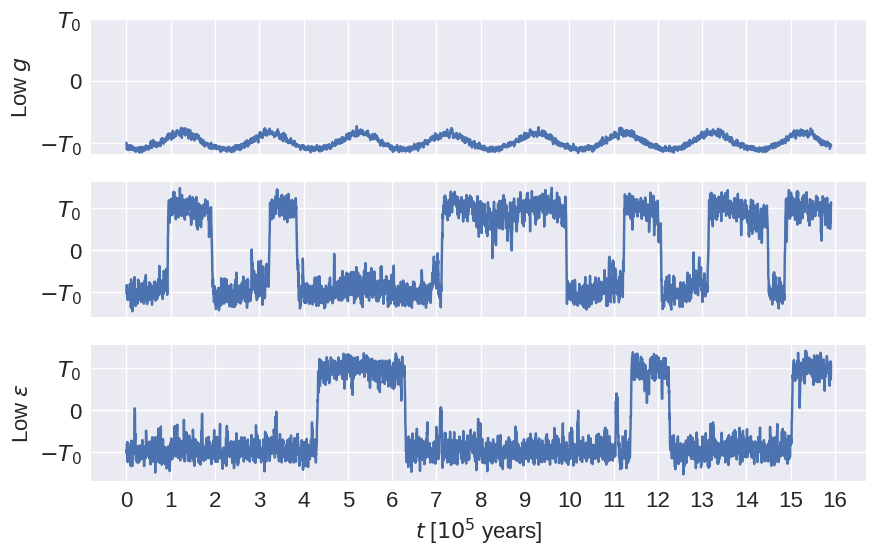

In [7]:
from numpy import *
from matplotlib import pyplot as plt
plt.style.use('seaborn-v0_8')

# Potential
def U(T, t, parameters):
  U_0, T_1, T_2, epsilon, w, g = parameters
  return 16*U_0 * (T-T_1)*(T-T_1) * (T-T_2)*(T-T_2) / (T_1-T_2)**(4) + epsilon*T*cos(w*t)

# Force due to the potential and extra force
def U_prime(T, t, parameters):
  U_0, T_1, T_2, epsilon, w, g = parameters
  return 32*U_0 * (T-T_1)*(T-T_2) * (2*T-T_1-T_2) / (T_1-T_2)**(4) + epsilon*cos(w*t-pi/4) # a phase has been added for style. It is not relevant for the discussion.


# Gaussian noise of mean 0 and standard deviation 1
def eta(dt):
  return random.normal(0,1)

def solve_langevin(parameters, tmax=400, PLOT=True):

  # Define time step and range
  t0 = 0
  dt = 0.001
  time_range = arange(t0, tmax, dt)

  # Save arrays for plotting
  save_frequency = tmax/4
  save_times = []
  save_T = []

  T = parameters[1] # initial value
  g = parameters[-1]
  for step, t in enumerate(time_range):

    D1 = -U_prime(T, t, parameters)
    D2 = g*g
    T = T + D1*dt + sqrt(D2*dt)*eta(t)
    if step%save_frequency == 0:
        save_T.append(T)
        save_times.append(t)

  # Plotting (optional)
  if PLOT == True:
    T_2 = parameters[2]
    plt.style.use('seaborn-v0_8')
    fig, ax = plt.subplots(figsize=(12, 3))
    ax.plot(save_times, save_T)
    ax.set_xticks(arange(0, pi/w*17, pi/w), arange(0, 17, 1), fontsize=16)
    ax.set_xlabel(r'$t$ [$10^5$ years]', fontsize=16)
    ax.set_yticks(arange(-2*T_2, 3*T_2, T_2), [r'$-2T_0$', r'$-T_0$', '0', r'$T_0$', r'$2T_0$'], fontsize=16)
    ax.set_ylabel(r'$T$', fontsize=16)
    plt.tight_layout()
    plt.savefig('EstMec_1_StochasticResonance.png', dpi=600)
    plt.show()

  return save_times, save_T

# Figure 3: Comparison between different values of noise and amplitude. Everything else is fixed.
fig, ax = plt.subplots(3, 1, figsize = (10,6), sharex=True)
T_2 = 10
# Low noise
ax1 = ax[0]
x, y = solve_langevin([100, -10, 10, 10, 0.25/2, 1], PLOT=False) #epsilon = 10, omega= 0.25/2, g = 1
ax1.plot(x, y)
ax1.set_yticks(arange(-T_2, 2*T_2, T_2), [r'$-T_0$', '0', r'$T_0$'], fontsize=16)
ax1.set_ylabel(r'Low $g$', fontsize=16)

# High noise, high force strength
ax2 = ax[1]
x, y = solve_langevin([100, -10, 10, 10, 0.25/2, 7], PLOT=False) #epsilon = 10, omega= 0.25/2, g = 7
ax2.plot(x, y)
ax2.set_yticks(arange(-T_2, 2*T_2, T_2), [r'$-T_0$', '0', r'$T_0$'], fontsize=16)

# Low force strength
ax3 = ax[2]
x, y = solve_langevin([100, -10, 10, 1, 0.25/2, 7], PLOT=False) #epsilon = 1, omega= 0.25/2, g = 7
ax3.plot(x, y)
ax3.set_yticks(arange(-T_2, 2*T_2, T_2), [r'$-T_0$', '0', r'$T_0$'], fontsize=16)
w = 0.25/2
ax3.set_xticks(arange(0, pi/w*17, pi/w), arange(0, 17, 1), fontsize=16)
ax3.set_xlabel(r'$t$ [$10^5$ years]', fontsize=16)
ax3.set_ylabel(r'Low $\varepsilon$', fontsize=16)

plt.savefig('EstMec_3_ComparisonAmplitude.png', dpi=600)
plt.show()

## Comparações de $g$ e $ϵ$

### Código Atualizado para 20 tempos de teste + Atualização para qualquer tmax

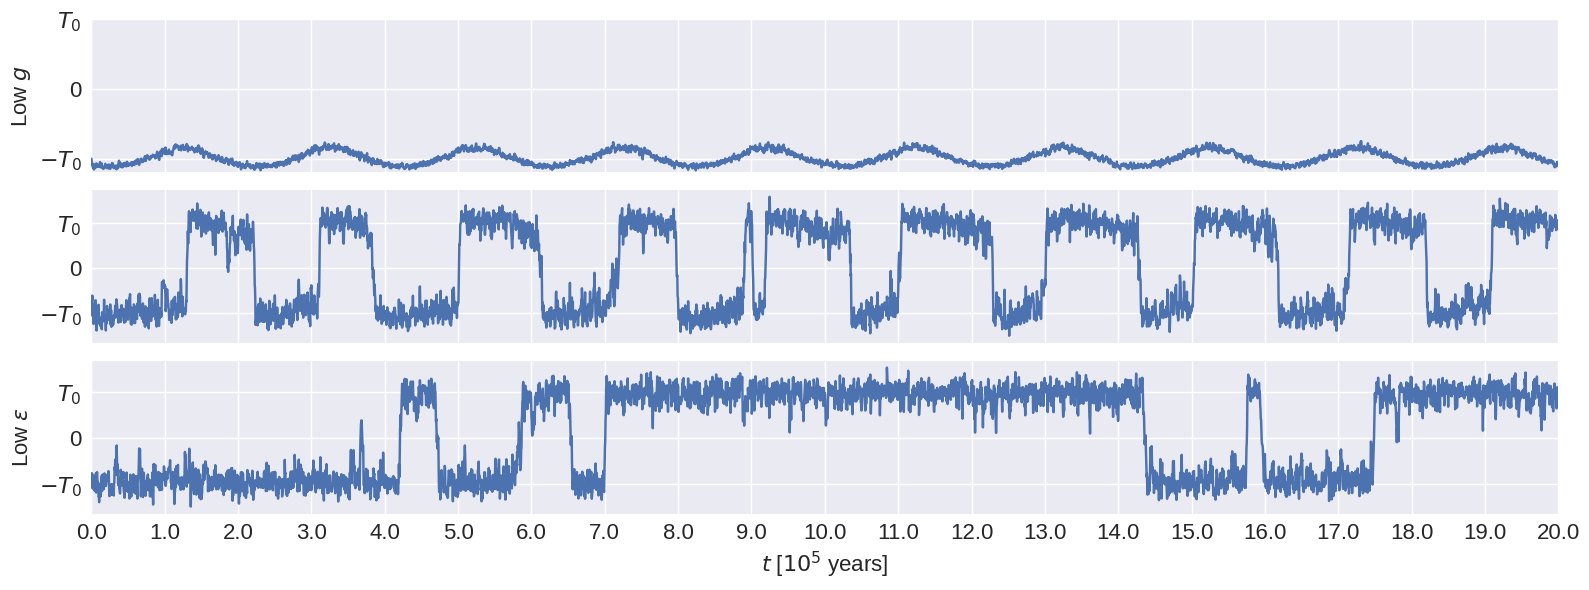

In [8]:
from matplotlib import pyplot as plt
from numpy import *

plt.style.use("seaborn-v0_8")


# Potential
def U(T, t, parameters):
    U_0, T_1, T_2, epsilon, w, g = parameters
    return (
        16
        * U_0
        * (T - T_1)
        * (T - T_1)
        * (T - T_2)
        * (T - T_2)
        / (T_1 - T_2) ** (4)
        + epsilon * T * cos(w * t)
    )


# Force due to the potential and extra force
def U_prime(T, t, parameters):
    U_0, T_1, T_2, epsilon, w, g = parameters
    return 32 * U_0 * (T - T_1) * (T - T_2) * (2 * T - T_1 - T_2) / (
        T_1 - T_2
    ) ** (4) + epsilon * cos(w * t - pi / 4)


# Gaussian noise of mean 0 and standard deviation 1
def eta(dt):
    return random.normal(0, 1)


def solve_langevin(parameters, tmax=500, PLOT=True):
    # Descompacta parâmetros para disponibilizar 'w' no escopo local da função
    U_0, T_1, T_2, epsilon, w, g = parameters

    # Define time step and range
    t0 = 0
    dt = 0.001
    time_range = arange(t0, tmax, dt)

    # Save arrays for plotting
    dt_salvo = 0.1  # intervalo de observação desejado
    passos = int(dt_salvo / dt)  # CORREÇÃO 1: Conversão explícita para int

    save_times = []
    save_T = []

    T = parameters[1]  # valor inicial
    for step, t in enumerate(time_range):
        D1 = -U_prime(T, t, parameters)
        D2 = g * g
        T = T + D1 * dt + sqrt(D2 * dt) * eta(dt)

        if step % passos == 0:
            save_T.append(T)
            save_times.append(t)

    # Plotting (optional)
    if PLOT:
        total_periodos = round(tmax / (pi / w))
        plt.style.use("seaborn-v0_8")
        fig, ax = plt.subplots(figsize=(12, 3))
        ax.plot(save_times, save_T)
        ax.set_xticks(
            arange(0, pi / w * (total_periodos + 1), pi / w),
            arange(0, (total_periodos + 1), 1),
            fontsize=16,
        )
        ax.set_xlim(
            0, total_periodos * (pi / w)
        )
        ax.set_xlabel(r"$t$ [$10^5$ years]", fontsize=16)
        ax.set_yticks(
            arange(-2 * T_2, 3 * T_2, T_2),
            [r"$-2T_0$", r"$-T_0$", "0", r"$T_0$", r"$2T_0$"],
            fontsize=16,
        )
        ax.set_ylabel(r"$T$", fontsize=16)
        plt.tight_layout()
        plt.savefig("EstMec_1_StochasticResonance.png", dpi=600)
        plt.show()

    return save_times, save_T


# Figure 3: Comparison between different values of noise and amplitude.
fig, ax = plt.subplots(3, 1, figsize=(16, 6), sharex=True)
T_2 = 10
w = 0.25 / 2
tmax_fig3 = 502.65  # Tempo correspondente a exatamente 20 períodos completos

total_periodos_fig3 = round(tmax_fig3 / (pi / w))

# Low noise
ax1 = ax[0]
x, y = solve_langevin([100, -10, 10, 10, w, 1], tmax=tmax_fig3, PLOT=False)
ax1.plot(x, y)
ax1.set_yticks(
    arange(-T_2, 2 * T_2, T_2), [r"$-T_0$", "0", r"$T_0$"], fontsize=16
)
ax1.set_ylabel(r"Low $g$", fontsize=16)

# High noise, high force strength
ax2 = ax[1]
x, y = solve_langevin([100, -10, 10, 10, w, 7], tmax=tmax_fig3, PLOT=False)
ax2.plot(x, y)
ax2.set_yticks(
    arange(-T_2, 2 * T_2, T_2), [r"$-T_0$", "0", r"$T_0$"], fontsize=16
)

# Low force strength
ax3 = ax[2]
x, y = solve_langevin([100, -10, 10, 1, w, 7], tmax=tmax_fig3, PLOT=False)
ax3.plot(x, y)
ax3.set_yticks(
    arange(-T_2, 2 * T_2, T_2), [r"$-T_0$", "0", r"$T_0$"], fontsize=16
)
ax3.set_xticks(
    arange(0, pi / w * (total_periodos_fig3 + 1), pi / w),
    arange(0, (total_periodos_fig3 + 1), 1),
    fontsize=16,
)
ax3.set_xlim(
    0, total_periodos_fig3 * (pi / w)
)
ax3.set_xlabel(r"$t$ [$10^5$ years]", fontsize=16)
ax3.set_ylabel(r"Low $\varepsilon$", fontsize=16)

plt.tight_layout()
plt.savefig("EstMec_3_ComparisonAmplitude.png", dpi=600)
plt.show()

## Fixed $\epsilon$:

### Fixed High $ϵ$, $\omega$ = 0.125 e $g$ variável:

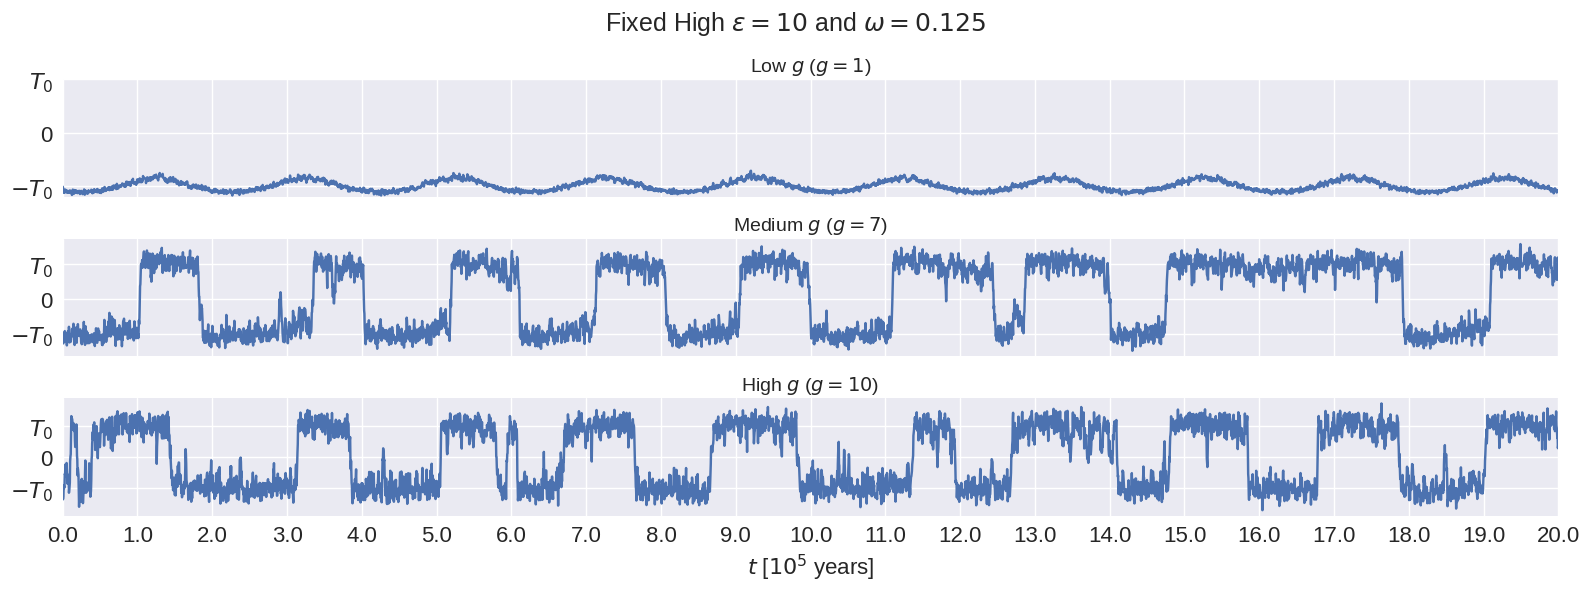

In [9]:
from matplotlib import pyplot as plt
from numpy import *

plt.style.use("seaborn-v0_8")


# Potential
def U(T, t, parameters):
    U_0, T_1, T_2, epsilon, w, g = parameters
    return (
        16
        * U_0
        * (T - T_1)
        * (T - T_1)
        * (T - T_2)
        * (T - T_2)
        / (T_1 - T_2) ** (4)
        + epsilon * T * cos(w * t)
    )


# Force due to the potential and extra force
def U_prime(T, t, parameters):
    U_0, T_1, T_2, epsilon, w, g = parameters
    return 32 * U_0 * (T - T_1) * (T - T_2) * (2 * T - T_1 - T_2) / (
        T_1 - T_2
    ) ** (4) + epsilon * cos(w * t - pi / 4)


# Gaussian noise of mean 0 and standard deviation 1
def eta(dt):
    return random.normal(0, 1)


def solve_langevin(parameters, tmax=500, PLOT=True):
    # Descompacta parâmetros para disponibilizar 'w' no escopo local da função
    U_0, T_1, T_2, epsilon, w, g = parameters

    # Define time step and range
    t0 = 0
    dt = 0.001
    time_range = arange(t0, tmax, dt)

    # Save arrays for plotting
    dt_salvo = 0.1  # intervalo de observação desejado
    passos = int(dt_salvo / dt)

    save_times = []
    save_T = []

    T = parameters[1]  # valor inicial
    for step, t in enumerate(time_range):
        D1 = -U_prime(T, t, parameters)
        D2 = g * g
        T = T + D1 * dt + sqrt(D2 * dt) * eta(dt)

        if step % passos == 0:
            save_T.append(T)
            save_times.append(t)

    # Plotting (optional)
    if PLOT:
        total_periodos = round(tmax / (pi / w))
        plt.style.use("seaborn-v0_8")
        fig, ax = plt.subplots(figsize=(12, 3))
        ax.plot(save_times, save_T)
        ax.set_xticks(
            arange(0, pi / w * (total_periodos + 1), pi / w),
            arange(0, (total_periodos + 1), 1),
            fontsize=16,
        )
        ax.set_xlim(
            0, total_periodos * (pi / w)
        )
        ax.set_xlabel(r"$t$ [$10^5$ years]", fontsize=16)
        ax.set_yticks(
            arange(-2 * T_2, 3 * T_2, T_2),
            [r"$-2T_0$", r"$-T_0$", "0", r"$T_0$", r"$2T_0$"],
            fontsize=16,
        )
        ax.set_ylabel(r"$T$", fontsize=16)
        plt.tight_layout()
        plt.savefig("EstMec_1_StochasticResonance.png", dpi=600)
        plt.show()

    return save_times, save_T


# Figure 3: Comparison between different values of noise and amplitude.
fig, ax = plt.subplots(3, 1, figsize=(16, 6), sharex=True)
T_2 = 10
w = 0.25 / 2
tmax_fig3 = 502.65  # Tempo correspondente a exatamente 20 períodos completos

total_periodos_fig3 = round(tmax_fig3 / (pi / w))

### EPSILON ALTO FIXO ####

# g baixo, omega fixo
ax1 = ax[0]
x, y = solve_langevin([100, -10, 10, 10, w, 1], tmax=tmax_fig3, PLOT=False) # epsilon = 10; w = 0.25/2; g = 1;
ax1.plot(x, y)
ax1.set_yticks(
    arange(-T_2, 2 * T_2, T_2), [r"$-T_0$", "0", r"$T_0$"], fontsize=16
)
ax1.set_title(r"Low $g$ ($g=1$)", fontsize=14)

# g médio, omega fixo
ax2 = ax[1]
x, y = solve_langevin([100, -10, 10, 10, w, 7], tmax=tmax_fig3, PLOT=False) # epsilon = 10; w = 0.25/2; g = 7;
ax2.plot(x, y)
ax2.set_yticks(
    arange(-T_2, 2 * T_2, T_2), [r"$-T_0$", "0", r"$T_0$"], fontsize=16
)
ax2.set_title(r"Medium $g$ ($g=7$)", fontsize=14)

# g alto, omega fixo
ax3 = ax[2]
x, y = solve_langevin([100, -10, 10, 10, w, 10], tmax=tmax_fig3, PLOT=False)
ax3.plot(x, y)
ax3.set_yticks(
    arange(-T_2, 2 * T_2, T_2), [r"$-T_0$", "0", r"$T_0$"], fontsize=16
)
ax3.set_xticks(
    arange(0, pi / w * (total_periodos_fig3 + 1), pi / w),
    arange(0, (total_periodos_fig3 + 1), 1),
    fontsize=16,
)
ax3.set_xlim(
    0, total_periodos_fig3 * (pi / w)
)
ax3.set_xlabel(r"$t$ [$10^5$ years]", fontsize=16)
ax3.set_title(r"High $g$ ($g=10$)", fontsize=14)

# Título geral para toda a figura
plt.suptitle(r"Fixed High $\varepsilon=10$ and $\omega = 0.125$", fontsize=18)

plt.tight_layout()
plt.savefig("EstMec_3_ComparisonAmplitude.png", dpi=600)
plt.show()

### Fixed Medium $\epsilon$, $\omega = 0.125$ e $g$ variável

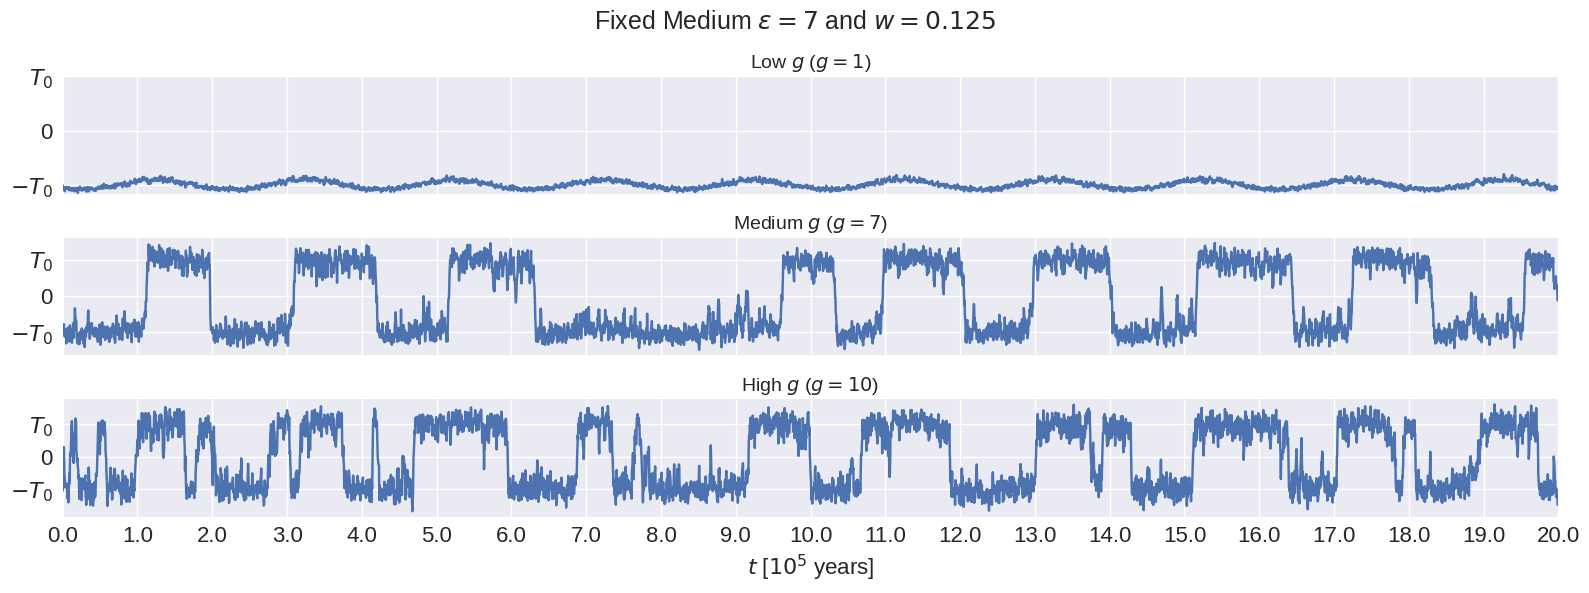

In [10]:
from matplotlib import pyplot as plt
from numpy import *

plt.style.use("seaborn-v0_8")


# Potential
def U(T, t, parameters):
    U_0, T_1, T_2, epsilon, w, g = parameters
    return (
        16
        * U_0
        * (T - T_1)
        * (T - T_1)
        * (T - T_2)
        * (T - T_2)
        / (T_1 - T_2) ** (4)
        + epsilon * T * cos(w * t)
    )


# Force due to the potential and extra force
def U_prime(T, t, parameters):
    U_0, T_1, T_2, epsilon, w, g = parameters
    return 32 * U_0 * (T - T_1) * (T - T_2) * (2 * T - T_1 - T_2) / (
        T_1 - T_2
    ) ** (4) + epsilon * cos(w * t - pi / 4)


# Gaussian noise of mean 0 and standard deviation 1
def eta(dt):
    return random.normal(0, 1)


def solve_langevin(parameters, tmax=500, PLOT=True):
    # Descompacta parâmetros para disponibilizar 'w' no escopo local da função
    U_0, T_1, T_2, epsilon, w, g = parameters

    # Define time step and range
    t0 = 0
    dt = 0.001
    time_range = arange(t0, tmax, dt)

    # Save arrays for plotting
    dt_salvo = 0.1  # intervalo de observação desejado
    passos = int(dt_salvo / dt)

    save_times = []
    save_T = []

    T = parameters[1]  # valor inicial
    for step, t in enumerate(time_range):
        D1 = -U_prime(T, t, parameters)
        D2 = g * g
        T = T + D1 * dt + sqrt(D2 * dt) * eta(dt)

        if step % passos == 0:
            save_T.append(T)
            save_times.append(t)

    # Plotting (optional)
    if PLOT:
        total_periodos = round(tmax / (pi / w))
        plt.style.use("seaborn-v0_8")
        fig, ax = plt.subplots(figsize=(12, 3))
        ax.plot(save_times, save_T)
        ax.set_xticks(
            arange(0, pi / w * (total_periodos + 1), pi / w),
            arange(0, (total_periodos + 1), 1),
            fontsize=16,
        )
        ax.set_xlim(
            0, total_periodos * (pi / w)
        )
        ax.set_xlabel(r"$t$ [$10^5$ years]", fontsize=16)
        ax.set_yticks(
            arange(-2 * T_2, 3 * T_2, T_2),
            [r"$-2T_0$", r"$-T_0$", "0", r"$T_0$", r"$2T_0$"],
            fontsize=16,
        )
        ax.set_ylabel(r"$T$", fontsize=16)
        plt.tight_layout()
        plt.savefig("EstMec_1_StochasticResonance.png", dpi=600)
        plt.show()

    return save_times, save_T


# Figure 3: Comparison between different values of noise and amplitude.
fig, ax = plt.subplots(3, 1, figsize=(16, 6), sharex=True)
T_2 = 10
w = 0.25 / 2
tmax_fig3 = 502.65  # Tempo correspondente a exatamente 20 períodos completos

total_periodos_fig3 = round(tmax_fig3 / (pi / w))

### EPSILON MÉDIO FIXO ####

# g baixo, omega fixo
ax1 = ax[0]
x, y = solve_langevin([100, -10, 10, 7, w, 1], tmax=tmax_fig3, PLOT=False) # epsilon = 7; w = 0.25/2; g = 1;
ax1.plot(x, y)
ax1.set_yticks(
    arange(-T_2, 2 * T_2, T_2), [r"$-T_0$", "0", r"$T_0$"], fontsize=16
)
ax1.set_title(r"Low $g$ ($g=1$)", fontsize=14)

# g médio, omega fixo
ax2 = ax[1]
x, y = solve_langevin([100, -10, 10, 7, w, 7], tmax=tmax_fig3, PLOT=False) # epsilon = 10; w = 0.25/2; g = 7;
ax2.plot(x, y)
ax2.set_yticks(
    arange(-T_2, 2 * T_2, T_2), [r"$-T_0$", "0", r"$T_0$"], fontsize=16
)
ax2.set_title(r"Medium $g$ ($g=7$)", fontsize=14)

# g alto, omega fixo
ax3 = ax[2]
x, y = solve_langevin([100, -10, 10, 7, w, 10], tmax=tmax_fig3, PLOT=False)
ax3.plot(x, y)
ax3.set_yticks(
    arange(-T_2, 2 * T_2, T_2), [r"$-T_0$", "0", r"$T_0$"], fontsize=16
)
ax3.set_xticks(
    arange(0, pi / w * (total_periodos_fig3 + 1), pi / w),
    arange(0, (total_periodos_fig3 + 1), 1),
    fontsize=16,
)
ax3.set_xlim(
    0, total_periodos_fig3 * (pi / w)
)
ax3.set_xlabel(r"$t$ [$10^5$ years]", fontsize=16)
ax3.set_title(r"High $g$ ($g=10$)", fontsize=14)

# Título geral para toda a figura
plt.suptitle(r"Fixed Medium $\varepsilon=7$ and $w = 0.125$", fontsize=18)

plt.tight_layout()
plt.savefig("EstMec_3_ComparisonAmplitude.png", dpi=600)
plt.show()

### Fixed Low $ϵ$ and $\omega = 0.125$ e $g$ variável

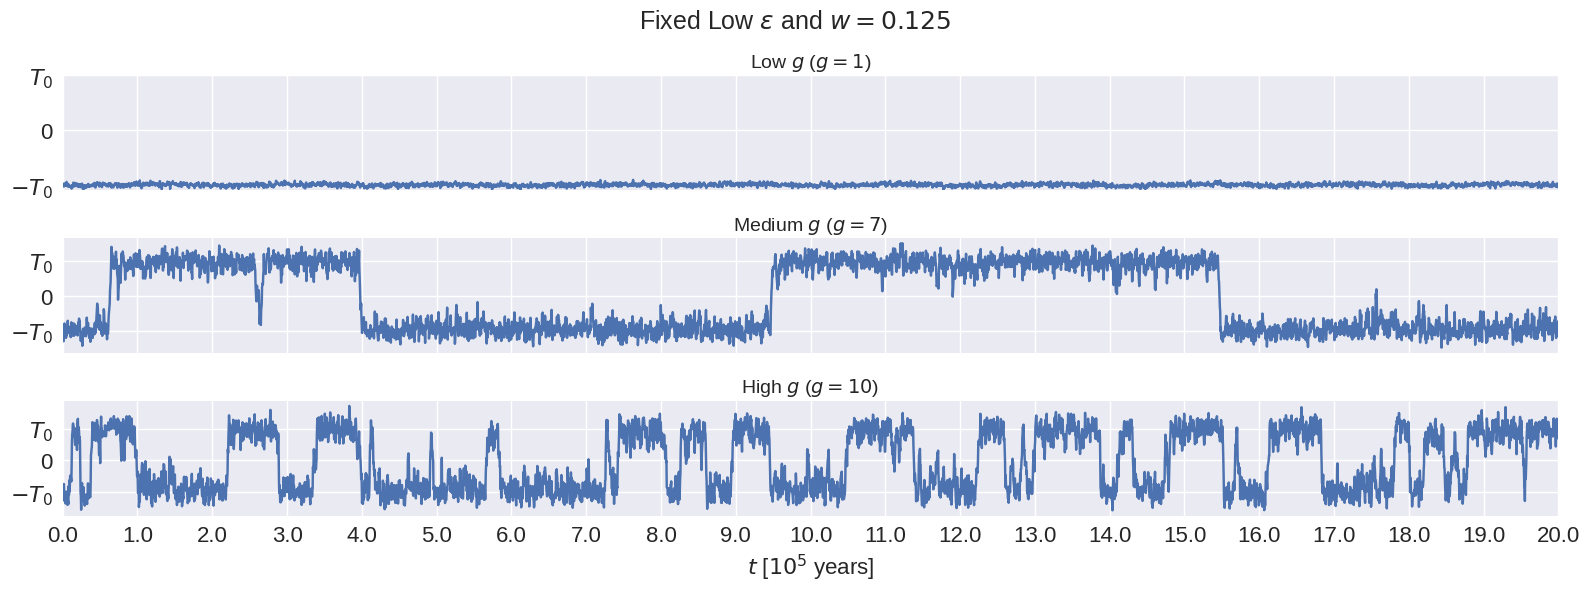

In [11]:
from matplotlib import pyplot as plt
from numpy import *

plt.style.use("seaborn-v0_8")


# Potential
def U(T, t, parameters):
    U_0, T_1, T_2, epsilon, w, g = parameters
    return (
        16
        * U_0
        * (T - T_1)
        * (T - T_1)
        * (T - T_2)
        * (T - T_2)
        / (T_1 - T_2) ** (4)
        + epsilon * T * cos(w * t)
    )


# Force due to the potential and extra force
def U_prime(T, t, parameters):
    U_0, T_1, T_2, epsilon, w, g = parameters
    return 32 * U_0 * (T - T_1) * (T - T_2) * (2 * T - T_1 - T_2) / (
        T_1 - T_2
    ) ** (4) + epsilon * cos(w * t - pi / 4)


# Gaussian noise of mean 0 and standard deviation 1
def eta(dt):
    return random.normal(0, 1)


def solve_langevin(parameters, tmax=500, PLOT=True):
    # Descompacta parâmetros para disponibilizar 'w' no escopo local da função
    U_0, T_1, T_2, epsilon, w, g = parameters

    # Define time step and range
    t0 = 0
    dt = 0.001
    time_range = arange(t0, tmax, dt)

    # Save arrays for plotting
    dt_salvo = 0.1  # intervalo de observação desejado
    passos = int(dt_salvo / dt)

    save_times = []
    save_T = []

    T = parameters[1]  # valor inicial
    for step, t in enumerate(time_range):
        D1 = -U_prime(T, t, parameters)
        D2 = g * g
        T = T + D1 * dt + sqrt(D2 * dt) * eta(dt)

        if step % passos == 0:
            save_T.append(T)
            save_times.append(t)

    # Plotting (optional)
    if PLOT:
        total_periodos = round(tmax / (pi / w))
        plt.style.use("seaborn-v0_8")
        fig, ax = plt.subplots(figsize=(12, 3))
        ax.plot(save_times, save_T)
        ax.set_xticks(
            arange(0, pi / w * (total_periodos + 1), pi / w),
            arange(0, (total_periodos + 1), 1),
            fontsize=16,
        )
        ax.set_xlim(
            0, total_periodos * (pi / w)
        )
        ax.set_xlabel(r"$t$ [$10^5$ years]", fontsize=16)
        ax.set_yticks(
            arange(-2 * T_2, 3 * T_2, T_2),
            [r"$-2T_0$", r"$-T_0$", "0", r"$T_0$", r"$2T_0$"],
            fontsize=16,
        )
        ax.set_ylabel(r"$T$", fontsize=16)
        plt.tight_layout()
        plt.savefig("EstMec_1_StochasticResonance.png", dpi=600)
        plt.show()

    return save_times, save_T


# Figure 3: Comparison between different values of noise and amplitude.
fig, ax = plt.subplots(3, 1, figsize=(16, 6), sharex=True)
T_2 = 10
w = 0.25 / 2
tmax_fig3 = 502.65  # Tempo correspondente a exatamente 20 períodos completos

total_periodos_fig3 = round(tmax_fig3 / (pi / w))

### EPSILON BAIXO FIXO ####

# g baixo, omega fixo
ax1 = ax[0]
x, y = solve_langevin([100, -10, 10, 1, w, 1], tmax=tmax_fig3, PLOT=False) # epsilon = 10; w = 0.25/2; g = 1;
ax1.plot(x, y)
ax1.set_yticks(
    arange(-T_2, 2 * T_2, T_2), [r"$-T_0$", "0", r"$T_0$"], fontsize=16
)
ax1.set_title(r"Low $g$ ($g=1$)", fontsize=14)

# g médio, omega fixo
ax2 = ax[1]
x, y = solve_langevin([100, -10, 10, 1, w, 7], tmax=tmax_fig3, PLOT=False) # epsilon = 10; w = 0.25/2; g = 7;
ax2.plot(x, y)
ax2.set_yticks(
    arange(-T_2, 2 * T_2, T_2), [r"$-T_0$", "0", r"$T_0$"], fontsize=16
)
ax2.set_title(r"Medium $g$ ($g=7$)", fontsize=14)

# g alto, omega fixo
ax3 = ax[2]
x, y = solve_langevin([100, -10, 10, 1, w, 10], tmax=tmax_fig3, PLOT=False)
ax3.plot(x, y)
ax3.set_yticks(
    arange(-T_2, 2 * T_2, T_2), [r"$-T_0$", "0", r"$T_0$"], fontsize=16
)
ax3.set_xticks(
    arange(0, pi / w * (total_periodos_fig3 + 1), pi / w),
    arange(0, (total_periodos_fig3 + 1), 1),
    fontsize=16,
)
ax3.set_xlim(
    0, total_periodos_fig3 * (pi / w)
)
ax3.set_xlabel(r"$t$ [$10^5$ years]", fontsize=16)
ax3.set_title(r"High $g$ ($g=10$)", fontsize=14)

# Título geral para toda a figura
plt.suptitle(r"Fixed Low $\varepsilon$ and $w = 0.125$", fontsize=18)

plt.tight_layout()
plt.savefig("EstMec_3_ComparisonAmplitude.png", dpi=600)
plt.show()

## Fixed g:

### Fixed High $g$, $\omega = 0.125$, $\epsilon$ variável

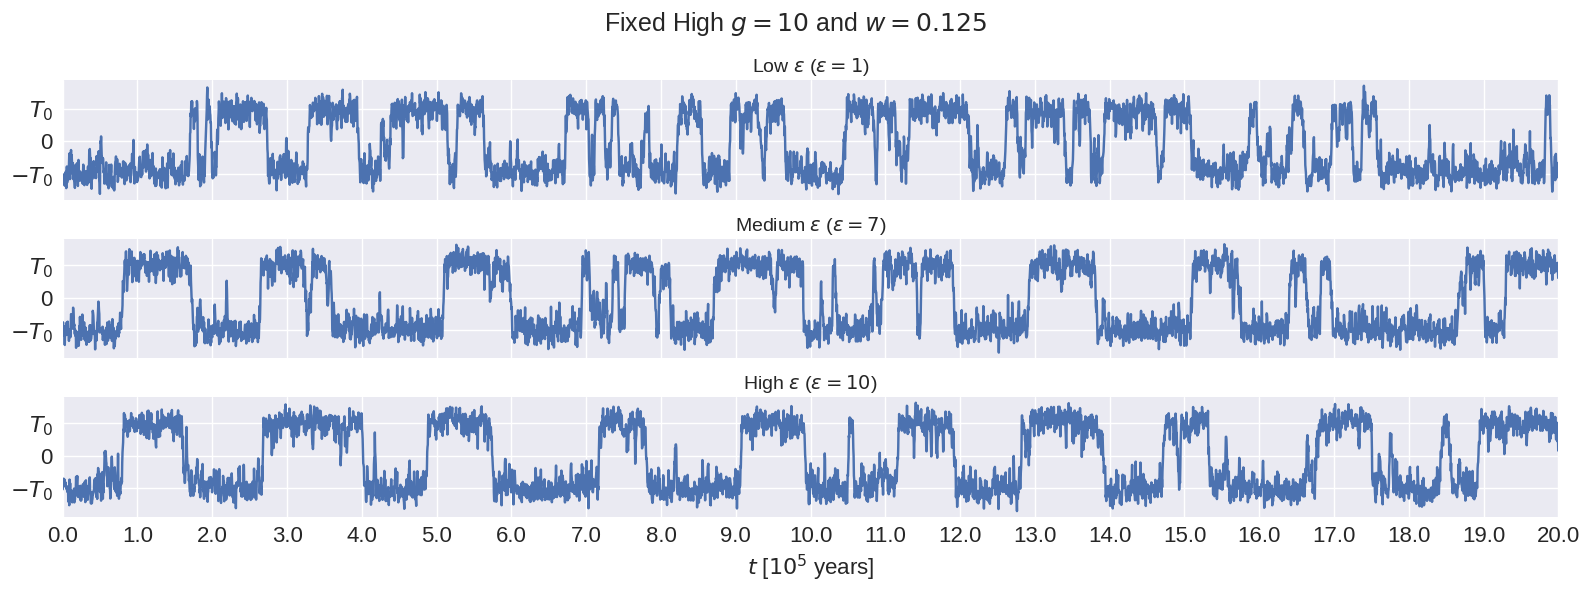

In [12]:
from matplotlib import pyplot as plt
from numpy import *

plt.style.use("seaborn-v0_8")


# Potential
def U(T, t, parameters):
    U_0, T_1, T_2, epsilon, w, g = parameters
    return (
        16
        * U_0
        * (T - T_1)
        * (T - T_1)
        * (T - T_2)
        * (T - T_2)
        / (T_1 - T_2) ** (4)
        + epsilon * T * cos(w * t)
    )


# Force due to the potential and extra force
def U_prime(T, t, parameters):
    U_0, T_1, T_2, epsilon, w, g = parameters
    return 32 * U_0 * (T - T_1) * (T - T_2) * (2 * T - T_1 - T_2) / (
        T_1 - T_2
    ) ** (4) + epsilon * cos(w * t - pi / 4)


# Gaussian noise of mean 0 and standard deviation 1
def eta(dt):
    return random.normal(0, 1)


def solve_langevin(parameters, tmax=500, PLOT=True):
    # Descompacta parâmetros para disponibilizar 'w' no escopo local da função
    U_0, T_1, T_2, epsilon, w, g = parameters

    # Define time step and range
    t0 = 0
    dt = 0.001
    time_range = arange(t0, tmax, dt)

    # Save arrays for plotting
    dt_salvo = 0.1  # intervalo de observação desejado
    passos = int(dt_salvo / dt)

    save_times = []
    save_T = []

    T = parameters[1]  # valor inicial
    for step, t in enumerate(time_range):
        D1 = -U_prime(T, t, parameters)
        D2 = g * g
        T = T + D1 * dt + sqrt(D2 * dt) * eta(dt)

        if step % passos == 0:
            save_T.append(T)
            save_times.append(t)

    # Plotting (optional)
    if PLOT:
        total_periodos = round(tmax / (pi / w))
        plt.style.use("seaborn-v0_8")
        fig, ax = plt.subplots(figsize=(12, 3))
        ax.plot(save_times, save_T)
        ax.set_xticks(
            arange(0, pi / w * (total_periodos + 1), pi / w),
            arange(0, (total_periodos + 1), 1),
            fontsize=16,
        )
        ax.set_xlim(
            0, total_periodos * (pi / w)
        )
        ax.set_xlabel(r"$t$ [$10^5$ years]", fontsize=16)
        ax.set_yticks(
            arange(-2 * T_2, 3 * T_2, T_2),
            [r"$-2T_0$", r"$-T_0$", "0", r"$T_0$", r"$2T_0$"],
            fontsize=16,
        )
        ax.set_ylabel(r"$T$", fontsize=16)
        plt.tight_layout()
        plt.savefig("EstMec_1_StochasticResonance.png", dpi=600)
        plt.show()

    return save_times, save_T


# Figure 3: Comparison between different values of noise and amplitude.
fig, ax = plt.subplots(3, 1, figsize=(16, 6), sharex=True)
T_2 = 10
w = 0.25 / 2
tmax_fig3 = 502.65  # Tempo correspondente a exatamente 20 períodos completos

total_periodos_fig3 = round(tmax_fig3 / (pi / w))

### G ALTO FIXO ####

# epsilon baixo, omega fixo
ax1 = ax[0]
x, y = solve_langevin([100, -10, 10, 1, w, 10], tmax=tmax_fig3, PLOT=False) # epsilon = 1; w = 0.25/2; g = 10;
ax1.plot(x, y)
ax1.set_yticks(
    arange(-T_2, 2 * T_2, T_2), [r"$-T_0$", "0", r"$T_0$"], fontsize=16
)
ax1.set_title(r"Low $\epsilon$ ($\epsilon=1$)", fontsize=14)

# epsilon médio, omega fixo
ax2 = ax[1]
x, y = solve_langevin([100, -10, 10, 7, w, 10], tmax=tmax_fig3, PLOT=False) # epsilon = 10; w = 0.25/2; g = 7;
ax2.plot(x, y)
ax2.set_yticks(
    arange(-T_2, 2 * T_2, T_2), [r"$-T_0$", "0", r"$T_0$"], fontsize=16
)
ax2.set_title(r"Medium $\epsilon$ ($\epsilon=7$)", fontsize=14)

# epsilon alto, omega fixo
ax3 = ax[2]
x, y = solve_langevin([100, -10, 10, 10, w, 10], tmax=tmax_fig3, PLOT=False)
ax3.plot(x, y)
ax3.set_yticks(
    arange(-T_2, 2 * T_2, T_2), [r"$-T_0$", "0", r"$T_0$"], fontsize=16
)
ax3.set_xticks(
    arange(0, pi / w * (total_periodos_fig3 + 1), pi / w),
    arange(0, (total_periodos_fig3 + 1), 1),
    fontsize=16,
)
ax3.set_xlim(
    0, total_periodos_fig3 * (pi / w)
)
ax3.set_xlabel(r"$t$ [$10^5$ years]", fontsize=16)
ax3.set_title(r"High $\epsilon$ ($\epsilon=10$)", fontsize=14)

# Título geral para toda a figura
plt.suptitle(r"Fixed High $g=10$ and $w = 0.125$", fontsize=18)

plt.tight_layout()
plt.savefig("EstMec_3_ComparisonAmplitude.png", dpi=600)
plt.show()

### Fixed Medium $g$, $\omega = 0.125$, $\epsilon$ variável

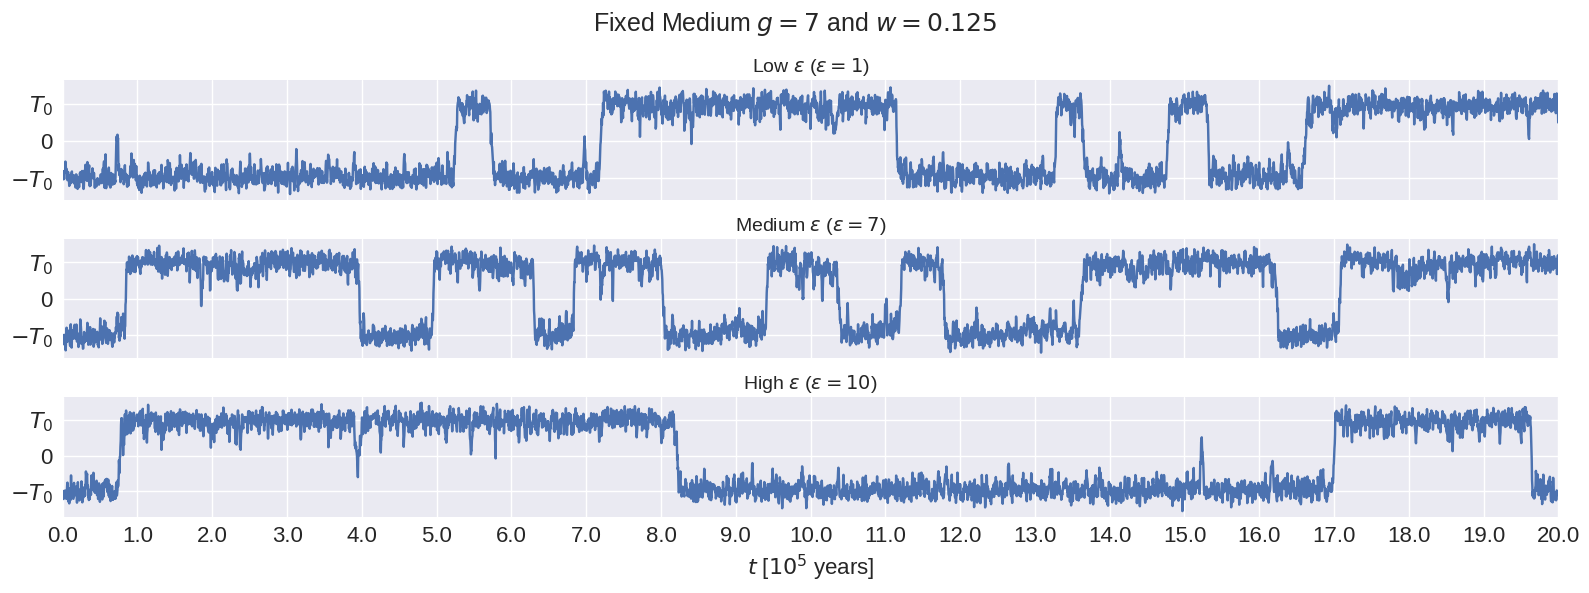

In [13]:
from matplotlib import pyplot as plt
from numpy import *

plt.style.use("seaborn-v0_8")


# Potential
def U(T, t, parameters):
    U_0, T_1, T_2, epsilon, w, g = parameters
    return (
        16
        * U_0
        * (T - T_1)
        * (T - T_1)
        * (T - T_2)
        * (T - T_2)
        / (T_1 - T_2) ** (4)
        + epsilon * T * cos(w * t)
    )


# Force due to the potential and extra force
def U_prime(T, t, parameters):
    U_0, T_1, T_2, epsilon, w, g = parameters
    return 32 * U_0 * (T - T_1) * (T - T_2) * (2 * T - T_1 - T_2) / (
        T_1 - T_2
    ) ** (4) + epsilon * cos(w * t - pi / 4)


# Gaussian noise of mean 0 and standard deviation 1
def eta(dt):
    return random.normal(0, 1)


def solve_langevin(parameters, tmax=500, PLOT=True):
    # Descompacta parâmetros para disponibilizar 'w' no escopo local da função
    U_0, T_1, T_2, epsilon, w, g = parameters

    # Define time step and range
    t0 = 0
    dt = 0.001
    time_range = arange(t0, tmax, dt)

    # Save arrays for plotting
    dt_salvo = 0.1  # intervalo de observação desejado
    passos = int(dt_salvo / dt)

    save_times = []
    save_T = []

    T = parameters[1]  # valor inicial
    for step, t in enumerate(time_range):
        D1 = -U_prime(T, t, parameters)
        D2 = g * g
        T = T + D1 * dt + sqrt(D2 * dt) * eta(dt)

        if step % passos == 0:
            save_T.append(T)
            save_times.append(t)

    # Plotting (optional)
    if PLOT:
        total_periodos = round(tmax / (pi / w))
        plt.style.use("seaborn-v0_8")
        fig, ax = plt.subplots(figsize=(12, 3))
        ax.plot(save_times, save_T)
        ax.set_xticks(
            arange(0, pi / w * (total_periodos + 1), pi / w),
            arange(0, (total_periodos + 1), 1),
            fontsize=16,
        )
        ax.set_xlim(
            0, total_periodos * (pi / w)
        )
        ax.set_xlabel(r"$t$ [$10^5$ years]", fontsize=16)
        ax.set_yticks(
            arange(-2 * T_2, 3 * T_2, T_2),
            [r"$-2T_0$", r"$-T_0$", "0", r"$T_0$", r"$2T_0$"],
            fontsize=16,
        )
        ax.set_ylabel(r"$T$", fontsize=16)
        plt.tight_layout()
        plt.savefig("EstMec_1_StochasticResonance.png", dpi=600)
        plt.show()

    return save_times, save_T


# Figure 3: Comparison between different values of noise and amplitude.
fig, ax = plt.subplots(3, 1, figsize=(16, 6), sharex=True)
T_2 = 10
w = 0.25 / 2
tmax_fig3 = 502.65  # Tempo correspondente a exatamente 20 períodos completos

total_periodos_fig3 = round(tmax_fig3 / (pi / w))

### G MÉDIO FIXO ####

# epsilon baixo, omega fixo
ax1 = ax[0]
x, y = solve_langevin([100, -10, 10, 1, w, 7], tmax=tmax_fig3, PLOT=False) # epsilon = 1; w = 0.25/2; g = 7;
ax1.plot(x, y)
ax1.set_yticks(
    arange(-T_2, 2 * T_2, T_2), [r"$-T_0$", "0", r"$T_0$"], fontsize=16
)
ax1.set_title(r"Low $\epsilon$ ($\epsilon=1$)", fontsize=14)

# epsilon médio, omega fixo
ax2 = ax[1]
x, y = solve_langevin([100, -10, 10, 7, w, 7], tmax=tmax_fig3, PLOT=False) # epsilon = 7; w = 0.25/2; g = 7;
ax2.plot(x, y)
ax2.set_yticks(
    arange(-T_2, 2 * T_2, T_2), [r"$-T_0$", "0", r"$T_0$"], fontsize=16
)
ax2.set_title(r"Medium $\epsilon$ ($\epsilon=7$)", fontsize=14)

# epsilon alto, omega fixo
ax3 = ax[2]
x, y = solve_langevin([100, -10, 10, 1, w, 7], tmax=tmax_fig3, PLOT=False)# epsilon = 1; w = 0.25/2; g = 7;
ax3.plot(x, y)
ax3.set_yticks(
    arange(-T_2, 2 * T_2, T_2), [r"$-T_0$", "0", r"$T_0$"], fontsize=16
)
ax3.set_xticks(
    arange(0, pi / w * (total_periodos_fig3 + 1), pi / w),
    arange(0, (total_periodos_fig3 + 1), 1),
    fontsize=16,
)
ax3.set_xlim(
    0, total_periodos_fig3 * (pi / w)
)
ax3.set_xlabel(r"$t$ [$10^5$ years]", fontsize=16)
ax3.set_title(r"High $\epsilon$ ($\epsilon=10$)", fontsize=14)

# Título geral para toda a figura
plt.suptitle(r"Fixed Medium $g=7$ and $w = 0.125$", fontsize=18)

plt.tight_layout()
plt.savefig("EstMec_3_ComparisonAmplitude.png", dpi=600)
plt.show()

### Fixed Low $g$, $\omega = 0.125$, $\epsilon$ variável

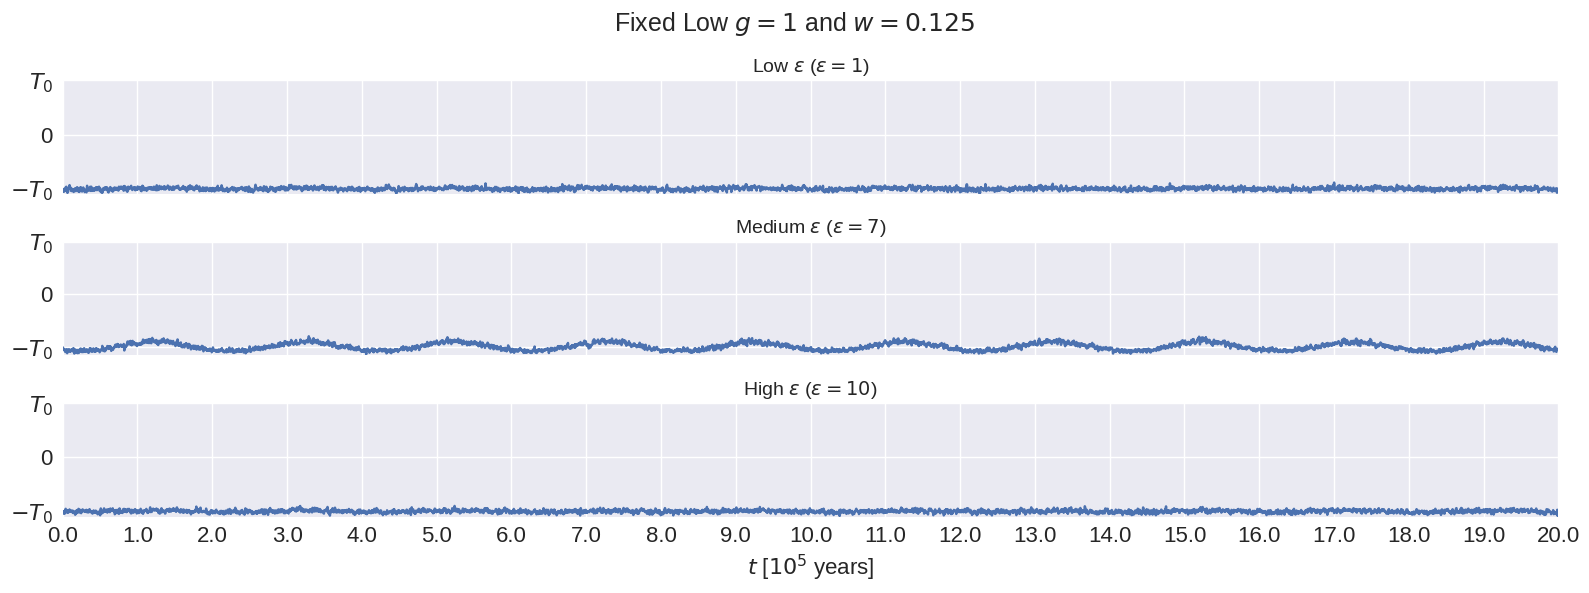

In [14]:
from matplotlib import pyplot as plt
from numpy import *

plt.style.use("seaborn-v0_8")


# Potential
def U(T, t, parameters):
    U_0, T_1, T_2, epsilon, w, g = parameters
    return (
        16
        * U_0
        * (T - T_1)
        * (T - T_1)
        * (T - T_2)
        * (T - T_2)
        / (T_1 - T_2) ** (4)
        + epsilon * T * cos(w * t)
    )


# Force due to the potential and extra force
def U_prime(T, t, parameters):
    U_0, T_1, T_2, epsilon, w, g = parameters
    return 32 * U_0 * (T - T_1) * (T - T_2) * (2 * T - T_1 - T_2) / (
        T_1 - T_2
    ) ** (4) + epsilon * cos(w * t - pi / 4)


# Gaussian noise of mean 0 and standard deviation 1
def eta(dt):
    return random.normal(0, 1)


def solve_langevin(parameters, tmax=500, PLOT=True):
    # Descompacta parâmetros para disponibilizar 'w' no escopo local da função
    U_0, T_1, T_2, epsilon, w, g = parameters

    # Define time step and range
    t0 = 0
    dt = 0.001
    time_range = arange(t0, tmax, dt)

    # Save arrays for plotting
    dt_salvo = 0.1  # intervalo de observação desejado
    passos = int(dt_salvo / dt)

    save_times = []
    save_T = []

    T = parameters[1]  # valor inicial
    for step, t in enumerate(time_range):
        D1 = -U_prime(T, t, parameters)
        D2 = g * g
        T = T + D1 * dt + sqrt(D2 * dt) * eta(dt)

        if step % passos == 0:
            save_T.append(T)
            save_times.append(t)

    # Plotting (optional)
    if PLOT:
        total_periodos = round(tmax / (pi / w))
        plt.style.use("seaborn-v0_8")
        fig, ax = plt.subplots(figsize=(12, 3))
        ax.plot(save_times, save_T)
        ax.set_xticks(
            arange(0, pi / w * (total_periodos + 1), pi / w),
            arange(0, (total_periodos + 1), 1),
            fontsize=16,
        )
        ax.set_xlim(
            0, total_periodos * (pi / w)
        )
        ax.set_xlabel(r"$t$ [$10^5$ years]", fontsize=16)
        ax.set_yticks(
            arange(-2 * T_2, 3 * T_2, T_2),
            [r"$-2T_0$", r"$-T_0$", "0", r"$T_0$", r"$2T_0$"],
            fontsize=16,
        )
        ax.set_ylabel(r"$T$", fontsize=16)
        plt.tight_layout()
        plt.savefig("EstMec_1_StochasticResonance.png", dpi=600)
        plt.show()

    return save_times, save_T


# Figure 3: Comparison between different values of noise and amplitude.
fig, ax = plt.subplots(3, 1, figsize=(16, 6), sharex=True)
T_2 = 10
w = 0.25 / 2
tmax_fig3 = 502.65  # Tempo correspondente a exatamente 20 períodos completos

total_periodos_fig3 = round(tmax_fig3 / (pi / w))

### G MÉDIO FIXO ####

# epsilon baixo, omega fixo
ax1 = ax[0]
x, y = solve_langevin([100, -10, 10, 1, w, 1], tmax=tmax_fig3, PLOT=False) # epsilon = 10; w = 0.25/2; g = 1;
ax1.plot(x, y)
ax1.set_yticks(
    arange(-T_2, 2 * T_2, T_2), [r"$-T_0$", "0", r"$T_0$"], fontsize=16
)
ax1.set_title(r"Low $\epsilon$ ($\epsilon=1$)", fontsize=14)

# epsilon médio, omega fixo
ax2 = ax[1]
x, y = solve_langevin([100, -10, 10, 7, w, 1], tmax=tmax_fig3, PLOT=False) # epsilon = 7; w = 0.25/2; g = 1;
ax2.plot(x, y)
ax2.set_yticks(
    arange(-T_2, 2 * T_2, T_2), [r"$-T_0$", "0", r"$T_0$"], fontsize=16
)
ax2.set_title(r"Medium $\epsilon$ ($\epsilon=7$)", fontsize=14)

# epsilon alto, omega fixo
ax3 = ax[2]
x, y = solve_langevin([100, -10, 10, 1, w, 1], tmax=tmax_fig3, PLOT=False)# epsilon = 1; w = 0.25/2; g = 1;
ax3.plot(x, y)
ax3.set_yticks(
    arange(-T_2, 2 * T_2, T_2), [r"$-T_0$", "0", r"$T_0$"], fontsize=16
)
ax3.set_xticks(
    arange(0, pi / w * (total_periodos_fig3 + 1), pi / w),
    arange(0, (total_periodos_fig3 + 1), 1),
    fontsize=16,
)
ax3.set_xlim(
    0, total_periodos_fig3 * (pi / w)
)
ax3.set_xlabel(r"$t$ [$10^5$ years]", fontsize=16)
ax3.set_title(r"High $\epsilon$ ($\epsilon=10$)", fontsize=14)

# Título geral para toda a figura
plt.suptitle(r"Fixed Low $g=1$ and $w = 0.125$", fontsize=18)

plt.tight_layout()
plt.savefig("EstMec_3_ComparisonAmplitude.png", dpi=600)
plt.show()

## Gráfico de Fases e Heatmap (Em construção)

### Função para calcular a Taxa de Karmers

In [15]:
def calcular_tau_kramers(U_0, T_1, T_2, g):
    # Altura da barreira
    Delta_U = U_0

    # Frequências da curvatura do potencial
    w_min = sqrt(32 * U_0) / abs(T_1 - T_2)
    w_max = sqrt(16 * U_0) / abs(T_1 - T_2)

    # Pre-fator e coeficiente de difusão
    pre_fator = (2 * pi) / (w_min * w_max)
    D = (g ** 2) / 2

    tau_k = pre_fator * exp(Delta_U / D)
    return tau_k

### Curva Clássica de Ressonância Estocástica (Indicador de Sincronização vs. Ruído g)

*  Eixo X: razão de tempos: $\tau_k / (\pi/\omega)$
*  Eixo Y: Grau de sincronização (Ex:Correlação cruzada $ρ$)
*  Destaque Linha Vertical no valor de g onde a teoria prevê $\tau_k$

In [16]:
def calcular_tau_kramers(U_0, T_1, T_2, g):
    # Altura da barreira
    Delta_U = U_0

    # Frequências da curvatura do potencial
    w_min = sqrt(32 * U_0) / abs(T_1 - T_2)
    w_max = sqrt(16 * U_0) / abs(T_1 - T_2)

    # Pre-fator e coeficiente de difusão
    pre_fator = (2 * pi) / (w_min * w_max)
    D = (g ** 2) / 2

    tau_k = pre_fator * exp(Delta_U / D)
    return tau_k

#### Correlação Cruzada:

* Mede o grau de alinhamento linear entre a resposta do sistema $T(t)$ e o sinal de entrada $S(t) = cos(\omega t)$